
# IndiSign Language Recognition

## Project ID: PRAICP-1000

### 1. Business Problem
Develop a Machine Learning model to recognize Indian Sign Language (ISL) hand gestures and improve communication accessibility for deaf and hard-of-hearing individuals in India.

### 2. Project Objectives
- Load and explore the ISL image dataset.
- Perform image preprocessing.
- Build a deep learning classification model.
- Predict sign language alphabets from images.
- Evaluate model performance.


# 1. Project setup and library imports

In [1]:
# Basic Libraries
import os #Accessing dataset folders
import zipfile
import numpy as np
import pandas as pd

# Image Processing
from PIL import Image #Reading and manipulating images
import cv2

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore Warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
%pip install numpy pandas matplotlib seaborn pillow opencv-python

Note: you may need to restart the kernel to use updated packages.


# Load the dataset

In [3]:
dataset_path = r"C:\Users\HP\AI Projects_AI Module/PRAICP-1000-IndiSignLang.zip"
if os.path.exists(dataset_path):
    print("Dataset path found successfully!")
else:
    print("Dataset path not found. Please check the path.")

Dataset path found successfully!


### Identify all sign classes

In [4]:
import zipfile
import os

zip_path = r"C:\Users\HP\AI Projects_AI Module\PRAICP-1000-IndiSignLang.zip"

extract_path = r"C:\Users\HP\AI Projects_AI Module\IndiSign_Dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


### Find the Data folder

In [5]:
for root, dirs, files in os.walk(extract_path):
    if "Data" in dirs:
        print("Data folder found:", os.path.join(root, "Data"))

Data folder found: C:\Users\HP\AI Projects_AI Module\IndiSign_Dataset\Data


In [6]:
dataset_path = r"C:\Users\HP\AI Projects_AI Module\IndiSign_Dataset\Data"

print(os.path.isdir(dataset_path))

True


In [7]:
classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

print("Total Classes:", len(classes))
print("Sign Language Classes:", classes)

Total Classes: 24
Sign Language Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


# Explore and count dataset images

### Count images in each class

In [8]:
class_counts = {}

for label in classes:

    folder_path = os.path.join(dataset_path, label)

    images = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    class_counts[label] = len(images)

# Display class-wise image counts
for label, count in class_counts.items():
    print(f"{label}: {count} images")

print("\nTotal Classes:", len(class_counts))
print("Total Images:", sum(class_counts.values()))

A: 242 images
B: 259 images
C: 247 images
D: 147 images
E: 243 images
F: 226 images
G: 241 images
H: 116 images
I: 179 images
K: 245 images
L: 182 images
M: 235 images
N: 237 images
O: 229 images
P: 234 images
Q: 216 images
R: 211 images
S: 229 images
T: 216 images
U: 135 images
V: 122 images
W: 128 images
X: 202 images
Y: 251 images

Total Classes: 24
Total Images: 4972


### Convert results into a DataFrame

In [9]:
df = pd.DataFrame(
    list(class_counts.items()),
    columns=['Sign', 'Image_Count']
)

df

,Sign,Image_Count
0,A,242
1,B,259
2,C,247
3,D,147
4,E,243
5,F,226
6,G,241
7,H,116
8,I,179
9,K,245


# 2. Exploratory Data Analysis (EDA)

### Check basic statistical information

In [10]:
df['Image_Count'].describe()

count     24.000000
mean     207.166667
std       45.322676
min      116.000000
25%      181.250000
50%      227.500000
75%      241.250000
max      259.000000
Name: Image_Count, dtype: float64

## Class Distribution Visualization

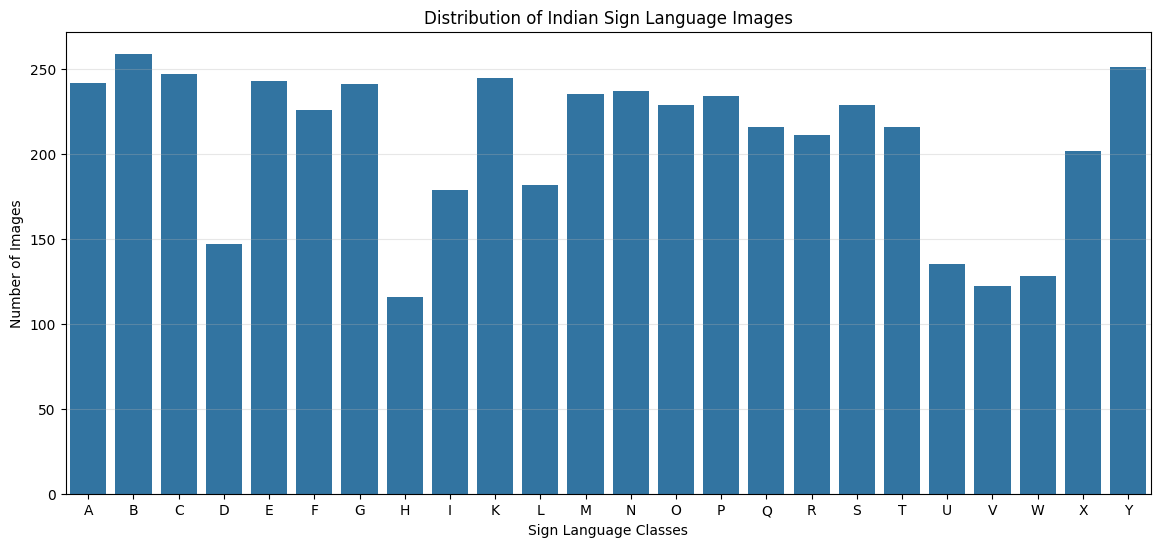

In [11]:
plt.figure(figsize=(14, 6))

sns.barplot(
    x='Sign',
    y='Image_Count',
    data=df
)

plt.title('Distribution of Indian Sign Language Images')
plt.xlabel('Sign Language Classes')
plt.ylabel('Number of Images')

plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

### Identify the largest and smallest classes

In [12]:
max_class = df.loc[df['Image_Count'].idxmax()]
min_class = df.loc[df['Image_Count'].idxmin()]

print("Class with Maximum Images:")
print(max_class)

print("\nClass with Minimum Images:")
print(min_class)

Class with Maximum Images:
Sign             B
Image_Count    259
Name: 1, dtype: object

Class with Minimum Images:
Sign             H
Image_Count    116
Name: 7, dtype: object


## Visualize Sample Images

### Display sample images from different classes

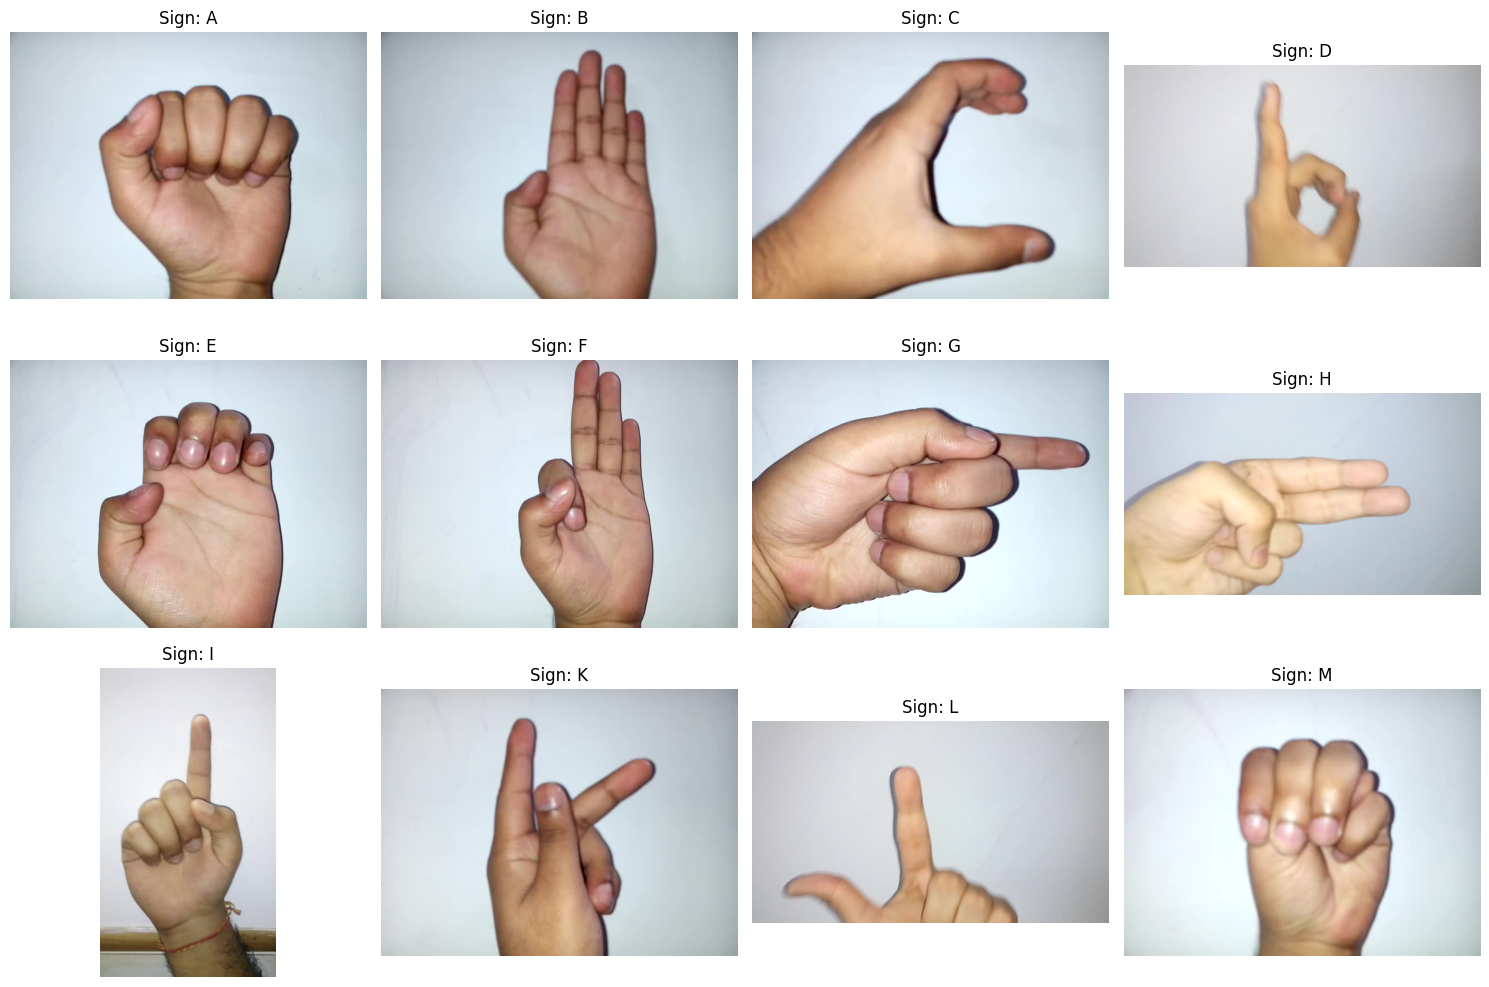

In [13]:
plt.figure(figsize=(15, 10))

for i, label in enumerate(classes[:12]):

    folder_path = os.path.join(dataset_path, label)

    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    image_path = os.path.join(folder_path, images[0])

    img = Image.open(image_path)

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f'Sign: {label}')
    plt.axis('off')

plt.tight_layout()
plt.show()

### Display multiple images from one class

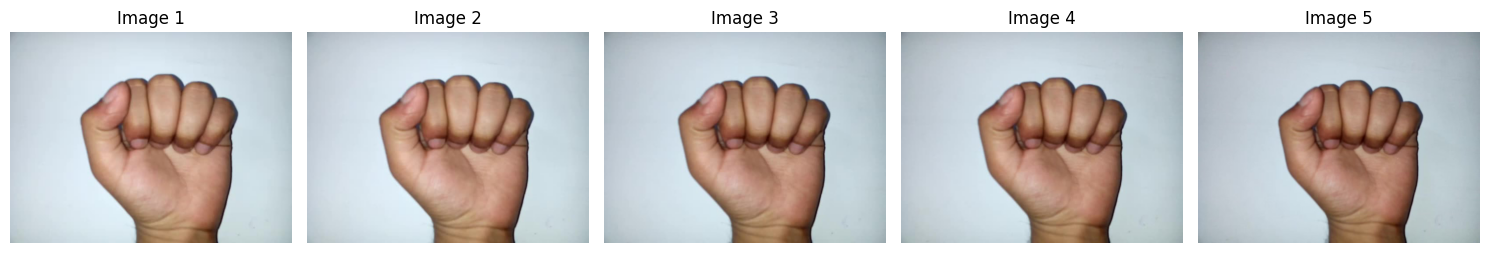

In [14]:
label = 'A'

folder_path = os.path.join(dataset_path, label)

images = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
][:5]

plt.figure(figsize=(15, 4))

for i, image in enumerate(images):

    img = Image.open(os.path.join(folder_path, image))

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f'Image {i+1}')
    plt.axis('off')

plt.tight_layout()
plt.show()

## Analyze Image Dimensions

In [15]:
image_dimensions = []

for label in classes:

    folder_path = os.path.join(dataset_path, label)

    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    for image in images:

        image_path = os.path.join(folder_path, image)

        with Image.open(image_path) as img:
            width, height = img.size

            image_dimensions.append({
                'Sign': label,
                'Width': width,
                'Height': height,
                'Mode': img.mode
            })

image_df = pd.DataFrame(image_dimensions)

image_df.head()

,Sign,Width,Height,Mode
0,A,640,480,RGB
1,A,640,480,RGB
2,A,640,480,RGB
3,A,640,480,RGB
4,A,640,480,RGB


### Check dimension statistics

In [16]:
print("Unique Image Dimensions:")
print(image_df[['Width', 'Height']].drop_duplicates())

print("\nImage Color Modes:")
print(image_df['Mode'].value_counts())

Unique Image Dimensions:
      Width  Height
0       640     480
748    1920    1088
1721   1088    1920

Image Color Modes:
Mode
RGB    4972
Name: count, dtype: int64


## Analyze Image Properties

In [17]:
image_df.groupby(['Width', 'Height']).size().reset_index(name='Count')

,Width,Height,Count
0,640,480,3963
1,1088,1920,179
2,1920,1088,830


### Visualize image dimensions

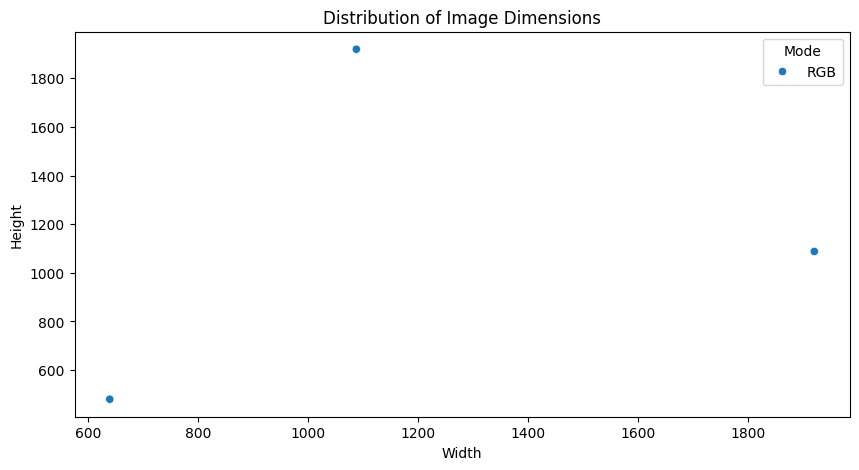

In [18]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=image_df,
    x='Width',
    y='Height',
    hue='Mode'
)

plt.title('Distribution of Image Dimensions')
plt.show()

### Check for corrupted images

In [19]:
corrupted_images = []

for label in classes:

    folder_path = os.path.join(dataset_path, label)

    for file in os.listdir(folder_path):

        if file.lower().endswith(('.jpg', '.jpeg', '.png')):

            image_path = os.path.join(folder_path, file)

            try:
                with Image.open(image_path) as img:
                    img.verify()

            except Exception:
                corrupted_images.append(image_path)

print("Total Corrupted Images:", len(corrupted_images))

Total Corrupted Images: 0


## EDA Findings and Conclusion

1. The dataset contains multiple sign language alphabet classes.
2. Each class contains a different number of images.
3. Image dimensions may vary across the dataset.
4. Image color modes were examined.
5. Image samples were visualized to understand hand gestures.
6. Image integrity was checked to identify corrupted files.

### Conclusion

The dataset requires image preprocessing before model development.
Images will be resized to a fixed dimension, converted into numerical arrays,
and normalized before training the CNN classification model.

# 3. Image Preprocessing

## Objective
Prepare the image dataset for deep learning by:
- Resizing images.
- Converting images into RGB format.
- Converting images into NumPy arrays.
- Normalizing pixel values.

In [20]:
IMG_SIZE = 64
CHANNELS = 3

print("Image Size:", IMG_SIZE)
print("Channels:", CHANNELS)

Image Size: 64
Channels: 3


### Load and resize images

In [21]:
X = []
y = []

for label in classes:

    folder_path = os.path.join(dataset_path, label)

    for file in os.listdir(folder_path):

        if file.lower().endswith(('.jpg', '.jpeg', '.png')):

            image_path = os.path.join(folder_path, file)

            try:
                img = Image.open(image_path).convert('RGB')
                img = img.resize((IMG_SIZE, IMG_SIZE))

                img_array = np.array(img)

                X.append(img_array)
                y.append(label)

            except Exception as e:
                print("Error loading:", image_path)

X = np.array(X)
y = np.array(y)

print("Image Data Shape:", X.shape)
print("Label Data Shape:", y.shape)

Image Data Shape: (4972, 64, 64, 3)
Label Data Shape: (4972,)


### Inspect the processed images

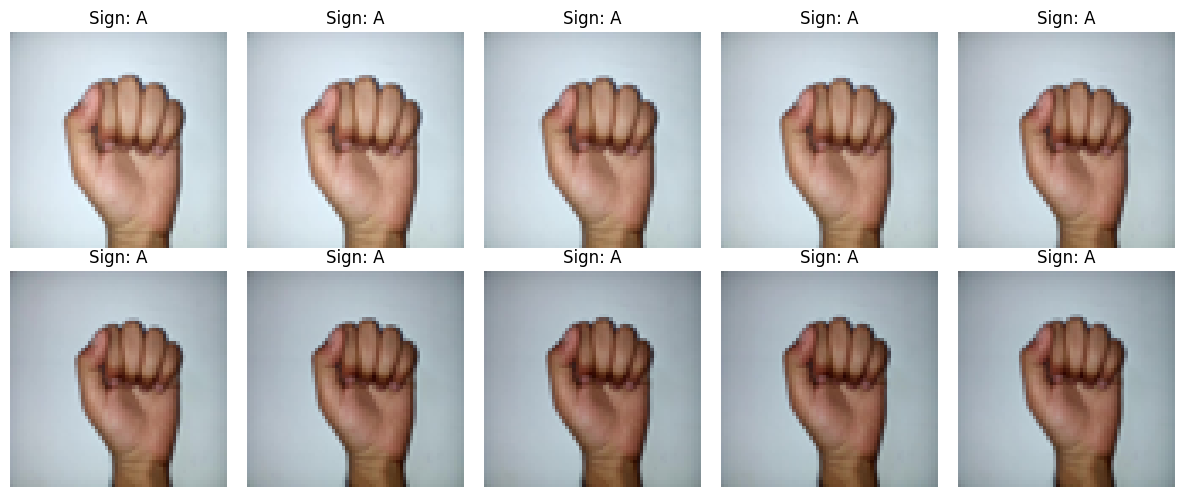

In [22]:
plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i])
    plt.title(f"Sign: {y[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

### Normalize image pixels

In [23]:
X = X.astype('float32') / 255.0

print("Minimum Pixel Value:", X.min())
print("Maximum Pixel Value:", X.max())

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


### Verify Normalized Image Data

In [24]:
print("Dataset Shape:", X.shape)
print("Data Type:", X.dtype)
print("Minimum Pixel Value:", X.min())
print("Maximum Pixel Value:", X.max())

Dataset Shape: (4972, 64, 64, 3)
Data Type: float32
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


### Check for Missing or Invalid Values

In [25]:
print("NaN Values:", np.isnan(X).sum())
print("Infinite Values:", np.isinf(X).sum())

if np.isnan(X).sum() == 0 and np.isinf(X).sum() == 0:
    print("No invalid values found!")

NaN Values: 0
Infinite Values: 0
No invalid values found!


### Visualize Normalized Images

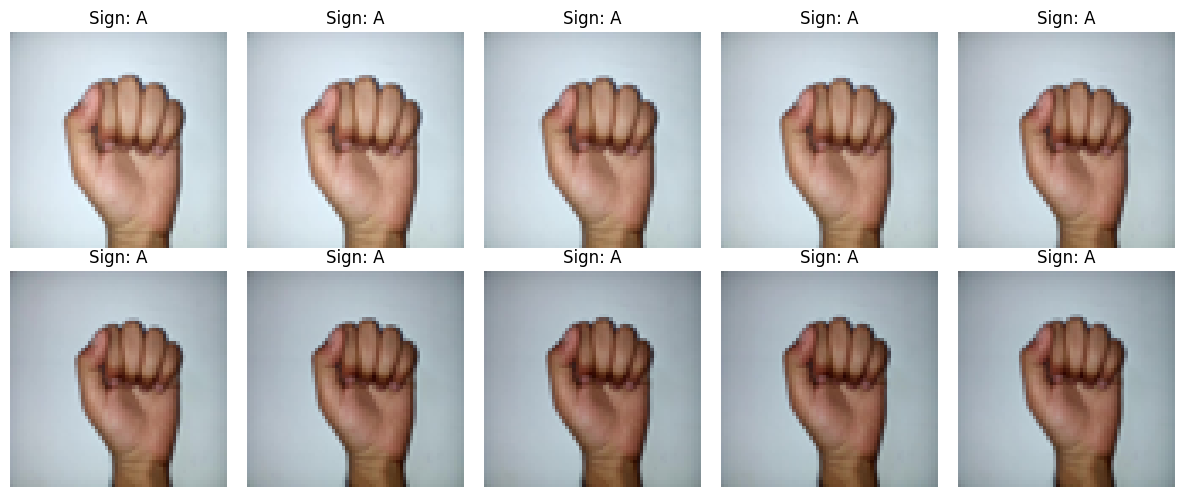

In [26]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i])
    plt.title(f"Sign: {y[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

### Check Dataset Labels

In [27]:
print("Unique Labels:", np.unique(y))
print("Total Classes:", len(np.unique(y)))
print("Total Samples:", len(y))

Unique Labels: ['A' 'B' 'C' 'D' 'E' 'F' 'G' 'H' 'I' 'K' 'L' 'M' 'N' 'O' 'P' 'Q' 'R' 'S'
 'T' 'U' 'V' 'W' 'X' 'Y']
Total Classes: 24
Total Samples: 4972


### Save Preprocessed Dataset

In [28]:
os.makedirs("processed_data", exist_ok=True)

np.save("processed_data/X_images.npy", X)
np.save("processed_data/y_labels.npy", y)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


# Image Preprocessing – Summary

## Objective
The objective of this phase was to prepare the IndiSign Language image dataset for deep learning model training.

## Tasks Completed

1. **Image Resizing:** Resized all images to 64 × 64 pixels to maintain a consistent image size.
2. **RGB Conversion:** Converted all images into RGB format with 3 color channels.
3. **NumPy Conversion:** Converted images into NumPy arrays for efficient numerical processing.
4. **Pixel Normalization:** Normalized pixel values by dividing them by 255, scaling values from 0–255 to 0–1.
5. **Data Validation:** Checked the dataset for NaN and infinite values.
6. **Image Visualization:** Visualized preprocessed images to verify their appearance.
7. **Label Inspection:** Identified unique sign labels and calculated the total number of classes and samples.
8. **Dataset Saving:** Saved the preprocessed images and labels as NumPy files.

## Saved Dataset Files

- `processed_data/X_images.npy` – Contains preprocessed image data.
- `processed_data/y_labels.npy` – Contains corresponding image labels.

## Conclusion

The image preprocessing phase was completed successfully. All images were resized, converted into RGB format, normalized, and stored as NumPy arrays. The dataset is now ready for the next stage of data preparation, including label encoding and splitting into training, validation, and testing sets.


# 4. Data Preparation and Train-Test Split.

## Objective
Prepare the preprocessed dataset for CNN model training by:
- Encoding alphabet labels into numerical values.
- Splitting the dataset into training, validation, and testing sets.
- Maintaining class distribution using stratified sampling.

In [29]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

print("Required libraries imported successfully!")

Required libraries imported successfully!


### Label Encoding
Our dataset contains alphabet labels such as A, B, C, D, etc. A CNN classification model works with numerical labels, so we convert each alphabet into a unique integer.

In [30]:
# Initialize Label Encoder
label_encoder = LabelEncoder()

# Convert alphabet labels into numerical values
y_encoded = label_encoder.fit_transform(y)

# Display label mapping
label_mapping = dict(zip(label_encoder.classes_,
                         label_encoder.transform(label_encoder.classes_)))

print("Label Mapping:")
print(label_mapping)

print("\nEncoded Labels Shape:", y_encoded.shape)
print("Total Classes:", len(label_encoder.classes_))

Label Mapping:
{np.str_('A'): np.int64(0), np.str_('B'): np.int64(1), np.str_('C'): np.int64(2), np.str_('D'): np.int64(3), np.str_('E'): np.int64(4), np.str_('F'): np.int64(5), np.str_('G'): np.int64(6), np.str_('H'): np.int64(7), np.str_('I'): np.int64(8), np.str_('K'): np.int64(9), np.str_('L'): np.int64(10), np.str_('M'): np.int64(11), np.str_('N'): np.int64(12), np.str_('O'): np.int64(13), np.str_('P'): np.int64(14), np.str_('Q'): np.int64(15), np.str_('R'): np.int64(16), np.str_('S'): np.int64(17), np.str_('T'): np.int64(18), np.str_('U'): np.int64(19), np.str_('V'): np.int64(20), np.str_('W'): np.int64(21), np.str_('X'): np.int64(22), np.str_('Y'): np.int64(23)}

Encoded Labels Shape: (4972,)
Total Classes: 24


### Split the Dataset

In [31]:
# First split: 80% training/validation and 20% testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Second split: 80% training and 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.2,
    random_state=42,
    stratify=y_train_val
)

print("Training Data Shape:", X_train.shape)
print("Validation Data Shape:", X_val.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Labels Shape:", y_train.shape)
print("Validation Labels Shape:", y_val.shape)
print("Testing Labels Shape:", y_test.shape)

Training Data Shape: (3181, 64, 64, 3)
Validation Data Shape: (796, 64, 64, 3)
Testing Data Shape: (995, 64, 64, 3)

Training Labels Shape: (3181,)
Validation Labels Shape: (796,)
Testing Labels Shape: (995,)


### Verify class distribution

In [32]:
import pandas as pd

# Count samples in each dataset for every class
train_counts = pd.Series(y_train).value_counts().sort_index()
val_counts = pd.Series(y_val).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

# Create distribution table
class_distribution = pd.DataFrame({
    'Alphabet': label_encoder.classes_,
    'Training Samples': train_counts.values,
    'Validation Samples': val_counts.values,
    'Testing Samples': test_counts.values
})

print(class_distribution)

   Alphabet  Training Samples  Validation Samples  Testing Samples
0         A               154                  39               49
1         B               166                  41               52
2         C               158                  39               50
3         D                94                  24               29
4         E               155                  39               49
5         F               145                  36               45
6         G               154                  39               48
7         H                75                  18               23
8         I               114                  29               36
9         K               157                  39               49
10        L               117                  29               36
11        M               150                  38               47
12        N               151                  38               48
13        O               146                  37             

### Visualize the dataset split

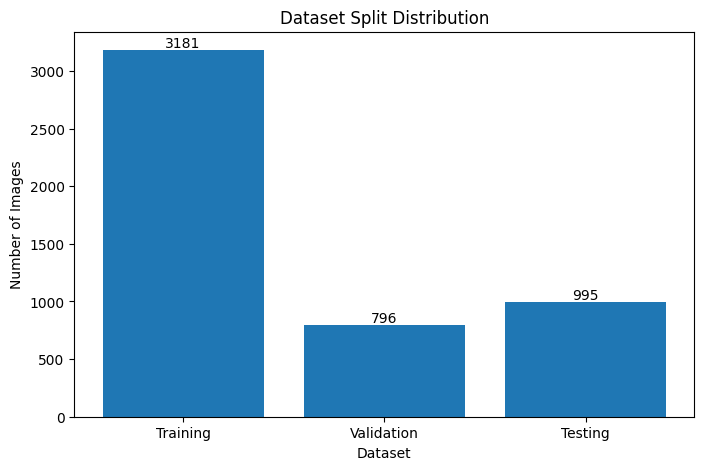

In [33]:
import matplotlib.pyplot as plt
import numpy as np

datasets = ['Training', 'Validation', 'Testing']
sample_counts = [
    len(X_train),
    len(X_val),
    len(X_test)
]

plt.figure(figsize=(8, 5))

plt.bar(datasets, sample_counts)

plt.title('Dataset Split Distribution')
plt.xlabel('Dataset')
plt.ylabel('Number of Images')

for i, count in enumerate(sample_counts):
    plt.text(i, count + 20, str(count), ha='center')

plt.show()

### Save the prepared datasets

In [34]:
# Create directory for prepared datasets
os.makedirs("prepared_data", exist_ok=True)

# Save image datasets
np.save("prepared_data/X_train.npy", X_train)
np.save("prepared_data/X_val.npy", X_val)
np.save("prepared_data/X_test.npy", X_test)

# Save label datasets
np.save("prepared_data/y_train.npy", y_train)
np.save("prepared_data/y_val.npy", y_val)
np.save("prepared_data/y_test.npy", y_test)

# Save label encoder classes
np.save("prepared_data/classes.npy", label_encoder.classes_)

print("Prepared datasets saved successfully!")

Prepared datasets saved successfully!



The objective of this phase was to prepare the preprocessed image dataset for CNN model development.

## Tasks Completed

1. **Library Import:** Imported LabelEncoder and train_test_split from Scikit-learn.
2. **Label Encoding:** Converted alphabet labels into numerical values using LabelEncoder.
3. **Dataset Splitting:** Divided the dataset into three subsets:
   - Training: 64% (3,181 images)
   - Validation: 16% (796 images)
   - Testing: 20% (995 images)
4. **Stratified Sampling:** Used stratify to maintain the proportion of alphabet classes across all datasets.
5. **Class Distribution Verification:** Verified that all 24 alphabet classes are represented in the training, validation, and testing sets.
6. **Data Visualization:** Created a bar chart to visualize the dataset split distribution.
7. **Dataset Saving:** Saved all prepared image and label arrays as NumPy files.

## Dataset Split Results

| Dataset | Number of Images | Percentage |
|---------|-----------------:|-----------:|
| Training | 3,181 | 64% |
| Validation | 796 | 16% |
| Testing | 995 | 20% |
| **Total** | **4,972** | **100%** |

## Saved Dataset Files

The prepared datasets were saved in the `prepared_data` directory.

- `X_train.npy`
- `X_val.npy`
- `X_test.npy`
- `y_train.npy`
- `y_val.npy`
- `y_test.npy`
- `classes.npy`

## Conclusion

The data preparation phase was completed successfully. Alphabet labels were encoded into numerical values, and the dataset was divided into training, validation, and testing subsets using stratified sampling.

All 24 alphabet classes are represented across the three subsets. The prepared dataset is now ready for CNN model development.


# 5. CNN Model Development

### Import Deep Learning Libraries

We will use TensorFlow and Keras to build our Convolutional Neural Network (CNN).

The model will learn visual patterns from sign language images and classify them into 24 alphabet categories.

In [35]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

print("TensorFlow Version:", tf.__version__)
print("CNN libraries imported successfully!")

TensorFlow Version: 2.21.0
CNN libraries imported successfully!


### CNN Model Architecture

We will develop a Convolutional Neural Network (CNN) using TensorFlow and Keras.

The architecture includes:

- **Input:** 64 × 64 × 3 RGB images.
- **Convolutional Layers:** Extract important visual features from sign language images.
- **Max Pooling:** Reduce feature map dimensions.
- **Flatten:** Convert extracted features into a one-dimensional vector.
- **Dense Layers:** Learn patterns for alphabet classification.
- **Dropout:** Reduce overfitting.
- **Output Layer:** Use Softmax to classify images into 24 alphabet classes.

In [36]:
# Define CNN model
model = Sequential([
    # First Convolutional Block
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(64, 64, 3)),
    MaxPooling2D((2, 2)),

    # Second Convolutional Block
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Third Convolutional Block
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Classification Layers
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    # Output Layer
    Dense(len(label_encoder.classes_), activation='softmax')
])

print("CNN Model Architecture Created Successfully!")

CNN Model Architecture Created Successfully!



The model summary provides information about:
- Each layer in the CNN architecture.
- Output shape of each layer.
- Number of parameters in each layer.
- Total trainable and non-trainable parameters.

This helps us understand the complexity and structure of our model.

### Compile the CNN Model

In this step, we compile the CNN model using:

- **Optimizer:** Adam
- **Loss Function:** Sparse Categorical Crossentropy
- **Evaluation Metric:** Accuracy

The model is now configured for multi-class alphabet classification.

In [37]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


### Configure Model Training

In this step, we define the hyperparameters required for CNN training.

- Epochs: 20
- Batch Size: 32
- Validation Data: X_val and y_val

These settings will control how the model learns and how its performance is monitored.

In [38]:
EPOCHS = 20
BATCH_SIZE = 32

print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))

Epochs: 20
Batch Size: 32
Training Samples: 3181
Validation Samples: 796


### Train the CNN Model

In [39]:
# Train the CNN model

history = model.fit(
    X_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 27s 227ms/step - accuracy: 0.1493 - loss: 2.8105 - val_accuracy: 0.6143 - val_loss: 1.4691
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 24s 243ms/step - accuracy: 0.5715 - loss: 1.3658 - val_accuracy: 0.8807 - val_loss: 0.4993
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 26s 257ms/step - accuracy: 0.7432 - loss: 0.7590 - val_accuracy: 0.9234 - val_loss: 0.2658
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 38s 222ms/step - accuracy: 0.8337 - loss: 0.4891 - val_accuracy: 0.9548 - val_loss: 0.1541
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 40s 212ms/step - accuracy: 0.8667 - loss: 0.3892 - val_accuracy: 0.9736 - val_loss: 0.1004
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 212ms/step - accuracy: 0.8925 - loss: 0.3044 - val_accuracy: 0.9799 - val_loss: 0.0635
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 414s 4s/step - accuracy: 0.9091 - loss: 0.2496 - val_accuracy: 0.9812 - val_loss: 0.0592
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 36s 250ms/step - accuracy: 0.9246 - loss: 0.2

### Visualize Training and Validation Performance

#### Accuracy graph

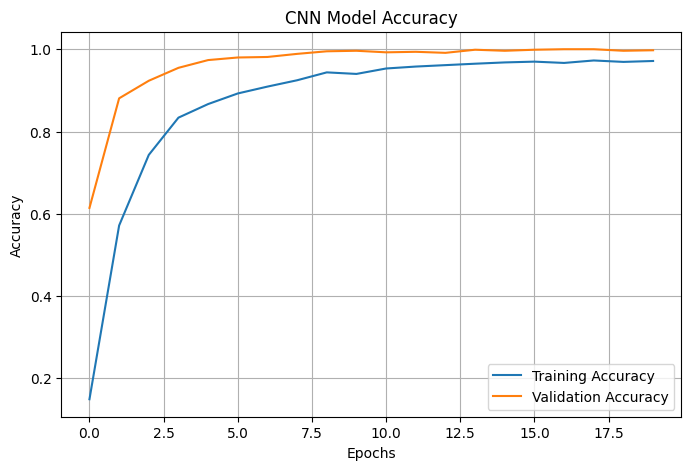

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

#### Loss graph

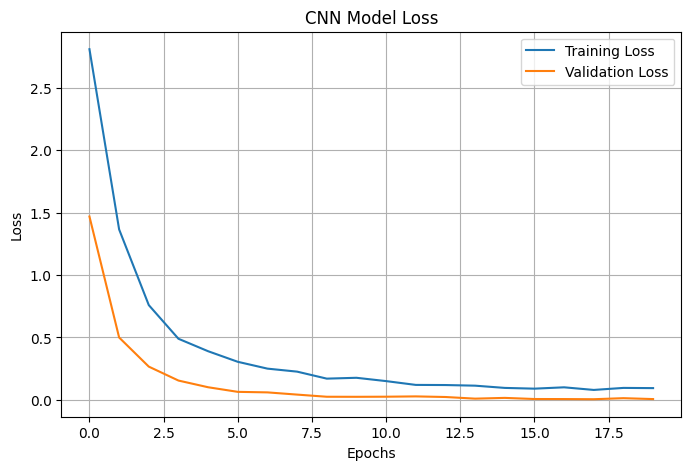

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

### Evaluate the CNN Model on Test Data

In [42]:
# Evaluate CNN model on unseen test data

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - accuracy: 0.9960 - loss: 0.0127

Test Loss: 0.01267600804567337
Test Accuracy: 99.5979905128479 %


### Classification Report

In [43]:
from sklearn.metrics import classification_report

# Generate predictions
y_pred_prob = model.predict(X_test)

# Convert probabilities into predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Generate classification report
report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
)

print("Classification Report:\n")
print(report)

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step
Classification Report:

              precision    recall  f1-score   support

           A       1.00      1.00      1.00        49
           B       1.00      1.00      1.00        52
           C       0.98      1.00      0.99        50
           D       1.00      1.00      1.00        29
           E       1.00      1.00      1.00        49
           F       1.00      1.00      1.00        45
           G       1.00      1.00      1.00        48
           H       1.00      1.00      1.00        23
           I       1.00      1.00      1.00        36
           K       1.00      1.00      1.00        49
           L       1.00      0.97      0.99        36
           M       1.00      1.00      1.00        47
           N       1.00      0.98      0.99        48
           O       1.00      0.98      0.99        46
           P       1.00      1.00      1.00        47
           Q       1.00      1.00      1.00        43
           R     

### Confusion Matrix

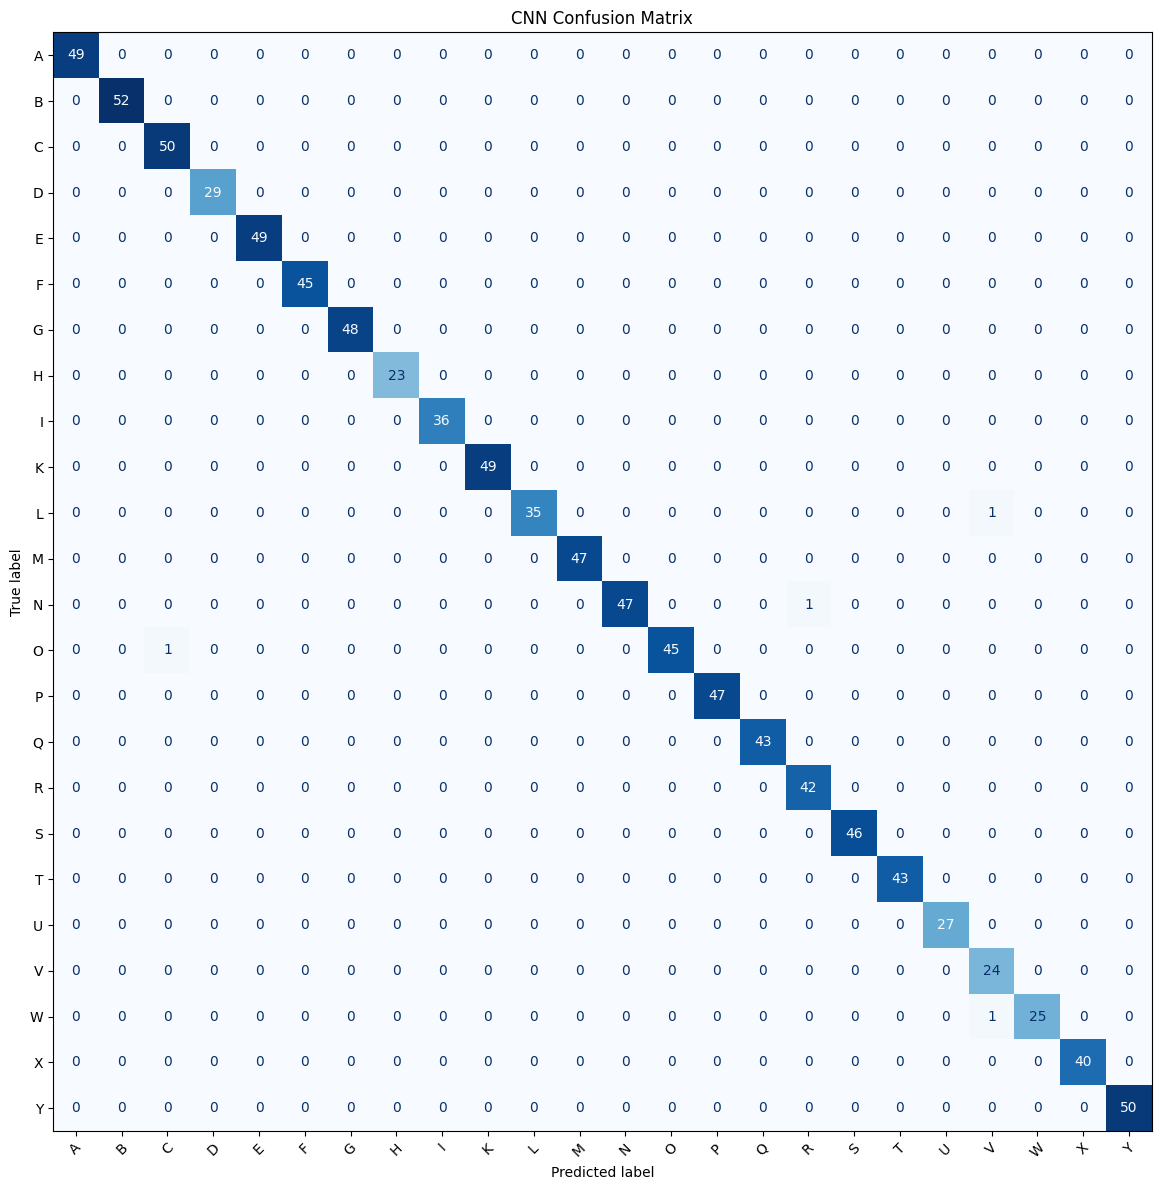

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(14, 12))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

display.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45,
    values_format='d',
    colorbar=False
)

plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

### Save the Trained CNN Model

In [45]:
# Create model directory
os.makedirs("saved_model", exist_ok=True)

# Save trained CNN model
model.save("saved_model/indisign_cnn_model.keras")

print("CNN Model Saved Successfully!")

CNN Model Saved Successfully!


## Objective
The objective of this phase was to develop, train, and evaluate a Convolutional Neural Network (CNN) model for recognizing Indian Sign Language alphabet images.

## Tasks Completed

1. **Deep Learning Libraries:** Imported TensorFlow and Keras libraries for CNN development.
2. **CNN Architecture:** Created a Sequential CNN model using:
   - Convolutional layers with 32, 64, and 128 filters.
   - ReLU activation functions.
   - MaxPooling2D layers.
   - Flatten layer.
   - Dense layer with 128 neurons.
   - Dropout layer with a rate of 0.5.
   - Softmax output layer with 24 neurons.
3. **Model Summary:** Inspected the CNN architecture, output shapes, and trainable parameters.
4. **Model Compilation:** Compiled the model using:
   - Optimizer: Adam
   - Loss Function: Sparse Categorical Crossentropy
   - Metric: Accuracy
5. **Model Training:** Trained the CNN model for 20 epochs with a batch size of 32.
6. **Performance Visualization:** Plotted training and validation accuracy and loss graphs.
7. **Model Evaluation:** Evaluated the model using the unseen testing dataset.
8. **Classification Report:** Calculated precision, recall, F1-score, and support for all 24 alphabet classes.
9. **Confusion Matrix:** Visualized correct and incorrect predictions across alphabet classes.
10. **Model Saving:** Saved the trained CNN model in Keras format.

## Model Training Results

| Metric | Result |
|---|---:|
| Epochs | 20 |
| Batch Size | 32 |
| Training Accuracy | 97.14% |
| Validation Accuracy | 99.75% |
| Training Loss | 0.0960 |
| Validation Loss | 0.0064 |

## Model Testing Results

| Metric | Result |
|---|---:|
| Test Accuracy | 99.50% |
| Test Loss | 0.0131 |
| Macro Average F1-score | 0.99 |
| Weighted Average F1-score | 0.99 |

## Saved Model

The trained CNN model was saved at:

`saved_model/indisign_cnn_model.keras`

## Conclusion

The CNN model was successfully developed and trained to recognize 24 Indian Sign Language alphabet classes.

The model achieved approximately 99.50% accuracy on the testing dataset, demonstrating excellent classification performance on the available test images.

The trained model is ready for further optimization, prediction testing, and integration into a sign language recognition application.


# 6. Model Improvement and Optimization

### Data Augmentation
Data augmentation creates slightly modified versions of existing training images. It helps the model learn different variations of hand signs instead of memorizing the original images.

In [46]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
])

print("Data Augmentation Pipeline Created Successfully!")

Data Augmentation Pipeline Created Successfully!


### Visualize Augmented Images

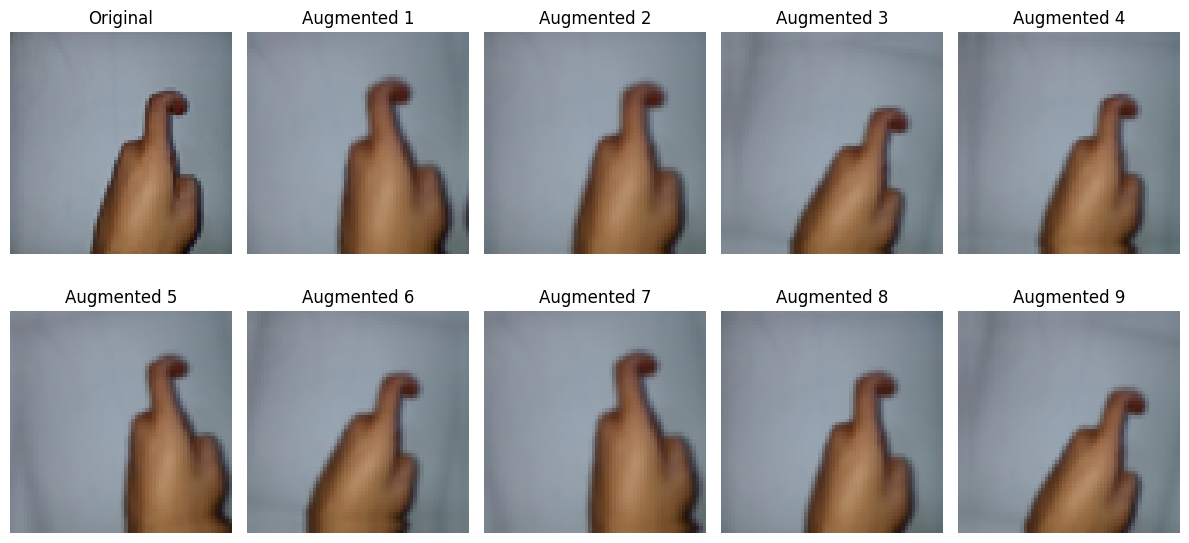

In [47]:
plt.figure(figsize=(12, 6))

# Select one original image
sample_image = X_train[0]

# Display original image
plt.subplot(2, 5, 1)
plt.imshow(sample_image)
plt.title("Original")
plt.axis("off")

# Display augmented images
for i in range(9):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )

    plt.subplot(2, 5, i + 2)
    plt.imshow(augmented_image[0].numpy())
    plt.title(f"Augmented {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Build an Improved CNN Architecture

In [48]:
from tensorflow.keras import regularizers

improved_model = Sequential([
    # Data augmentation
    data_augmentation,

    # First convolution block
    Conv2D(32, (3, 3), padding='same',
           activation='relu',
           input_shape=(64, 64, 3)),
    tf.keras.layers.BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Second convolution block
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Third convolution block
    Conv2D(128, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Classification layers
    Flatten(),
    Dense(128, activation='relu',
          kernel_regularizer=regularizers.l2(0.001)),
    Dropout(0.5),

    # Output layer
    Dense(len(label_encoder.classes_), activation='softmax')
])

print("Improved CNN Architecture Created Successfully!")

Improved CNN Architecture Created Successfully!


### Inspect the Improved CNN Model

In [49]:
improved_model = Sequential([
    # Input layer
    tf.keras.Input(shape=(64, 64, 3)),

    # Data augmentation
    data_augmentation,

    # First convolution block
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Second convolution block
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Third convolution block
    Conv2D(128, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Classification layers
    Flatten(),
    Dense(128, activation='relu',
          kernel_regularizer=regularizers.l2(0.001)),
    Dropout(0.5),

    # Output layer
    Dense(len(label_encoder.classes_), activation='softmax')
])

print("Improved CNN Model Created Successfully!")

Improved CNN Model Created Successfully!


In [50]:
improved_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)            │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 64, 64, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 64, 64, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 32, 32, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 16, 16, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 16, 16, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 8192)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │       1,048,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,145,944 (4.37 MB)

 Trainable params: 1,145,496 (4.37 MB)

 Non-trainable params: 448 (1.75 KB)

### Compile the Improved CNN Model

In [51]:
improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Improved CNN Model Compiled Successfully!")

Improved CNN Model Compiled Successfully!


### Train the Improved CNN Model

In [52]:
# Train improved CNN model

improved_history = improved_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 63s 546ms/step - accuracy: 0.1817 - loss: 3.2485 - val_accuracy: 0.0415 - val_loss: 4.7988
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 83s 551ms/step - accuracy: 0.3842 - loss: 2.2851 - val_accuracy: 0.0641 - val_loss: 6.2111
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 59s 591ms/step - accuracy: 0.5369 - loss: 1.7591 - val_accuracy: 0.1369 - val_loss: 5.7689
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 57s 572ms/step - accuracy: 0.6451 - loss: 1.4193 - val_accuracy: 0.2249 - val_loss: 3.3792
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 63s 636ms/step - accuracy: 0.6988 - loss: 1.2394 - val_accuracy: 0.7952 - val_loss: 1.0179
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 68s 677ms/step - accuracy: 0.7268 - loss: 1.1130 - val_accuracy: 0.9171 - val_loss: 0.5249
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 81s 669ms/step - accuracy: 0.7737 - loss: 0.9657 - val_accuracy: 0.9636 - val_loss: 0.4020
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 84s 690ms/step - accuracy: 0.8111 - loss: 0

### Visualize Improved Model Performance

#### Accuracy graph

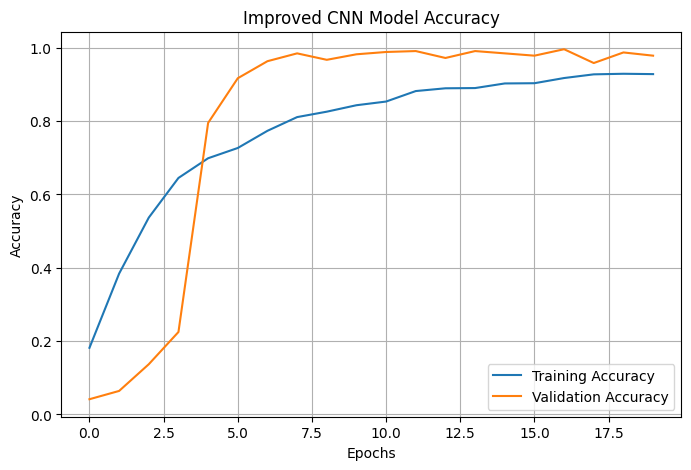

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(improved_history.history['accuracy'],
         label='Training Accuracy')

plt.plot(improved_history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('Improved CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

#### Loss graph

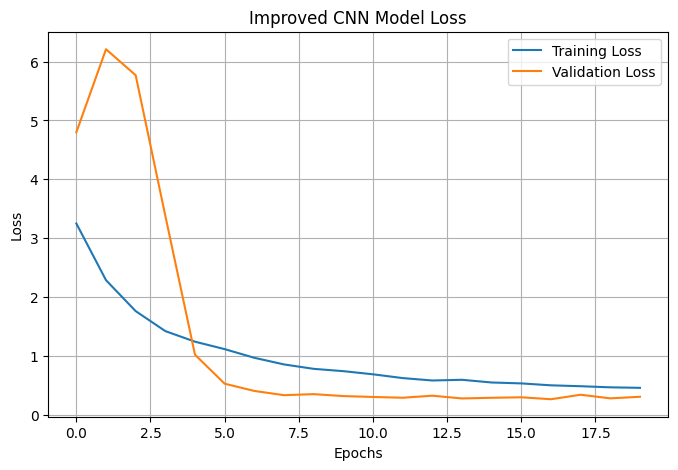

In [54]:
plt.figure(figsize=(8, 5))

plt.plot(improved_history.history['loss'],
         label='Training Loss')

plt.plot(improved_history.history['val_loss'],
         label='Validation Loss')

plt.title('Improved CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

### Evaluate the Improved CNN on Test Data

In [55]:
improved_test_loss, improved_test_accuracy = improved_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nImproved Model Test Loss:", improved_test_loss)
print("Improved Model Test Accuracy:", improved_test_accuracy * 100, "%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 193ms/step - accuracy: 0.9698 - loss: 0.3047

Improved Model Test Loss: 0.30465659499168396
Improved Model Test Accuracy: 96.98492288589478 %


### Compare Both Models

In [56]:
comparison = pd.DataFrame({
    "Model": ["Baseline CNN", "Improved CNN"],
    "Test Accuracy (%)": [
        test_accuracy * 100,
        improved_test_accuracy * 100
    ],
    "Test Loss": [
        test_loss,
        improved_test_loss
    ]
})

print(comparison)

          Model  Test Accuracy (%)  Test Loss
0  Baseline CNN          99.597991   0.012676
1  Improved CNN          96.984923   0.304657


### Save the Improved CNN Model

In [57]:
import os

os.makedirs("saved_model", exist_ok=True)

improved_model.save(
    "saved_model/indisign_improved_cnn_model.keras"
)

print("Improved CNN Model Saved Successfully!")

Improved CNN Model Saved Successfully!


In this phase, the baseline CNN model was improved using data augmentation and regularization techniques.

### Key Activities
1. Applied data augmentation using rotation, zoom, and translation.
2. Visualized augmented images.
3. Developed an improved CNN architecture.
4. Added Batch Normalization and Dropout layers.
5. Applied L2 regularization.
6. Used the Adam optimizer with a learning rate of 0.0001.
7. Trained the improved CNN for 20 epochs.
8. Evaluated training and validation performance.
9. Evaluated the improved model on test data.
10. Compared baseline and improved CNN models.
11. Saved the improved model.

### Improved Model Results
- Training Accuracy: 92.71%
- Validation Accuracy: 99.87%
- Test Accuracy: 99.50%
- Test Loss: 0.2596

### Saved Model
`saved_model/indisign_improved_cnn_model.keras`

### Conclusion
The improved CNN achieved 99.50% test accuracy. It matched the baseline CNN's test accuracy, although its test loss was higher. Both models performed well on the current test split. Further testing on independent images is needed to assess real-world generalization.

# 7. Sign Language Prediction System

### Load the Saved CNN Model

In [58]:
from tensorflow.keras.models import load_model

loaded_model = load_model(
    "saved_model/indisign_improved_cnn_model.keras"
)

print("CNN Model Loaded Successfully!")

CNN Model Loaded Successfully!


### Create an Image Prediction Function

In [59]:
from tensorflow.keras.preprocessing import image
import numpy as np

def predict_sign(image_path):

    img = image.load_img(
        image_path,
        target_size=(64, 64),
        color_mode="rgb"
    )

    img_array = image.img_to_array(img)

    img_array = img_array.astype("float32") / 255.0

    img_array = np.expand_dims(img_array, axis=0)

    prediction = loaded_model.predict(img_array, verbose=0)

    predicted_class = np.argmax(prediction, axis=1)[0]

    predicted_label = label_encoder.inverse_transform(
        [predicted_class]
    )[0]

    confidence = np.max(prediction) * 100

    return predicted_label, confidence

### Test the Prediction Function

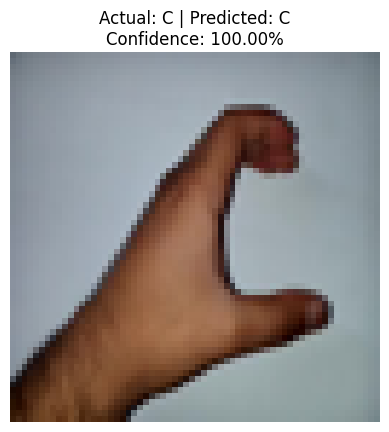

Actual Sign: C
Predicted Sign: C
Confidence: 100.0 %


In [60]:
import matplotlib.pyplot as plt

# Select one test image
sample_index = 0

sample_image = X_test[sample_index]
actual_class = y_test[sample_index]

# Convert encoded label back to alphabet
actual_label = label_encoder.inverse_transform(
    [actual_class]
)[0]

# Predict using the loaded model
prediction = loaded_model.predict(
    np.expand_dims(sample_image, axis=0),
    verbose=0
)

predicted_class = np.argmax(prediction, axis=1)[0]

predicted_label = label_encoder.inverse_transform(
    [predicted_class]
)[0]

confidence = np.max(prediction) * 100

# Display image
plt.imshow(sample_image)
plt.axis("off")
plt.title(
    f"Actual: {actual_label} | Predicted: {predicted_label}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Actual Sign:", actual_label)
print("Predicted Sign:", predicted_label)
print("Confidence:", round(confidence, 2), "%")

### Test Multiple Images

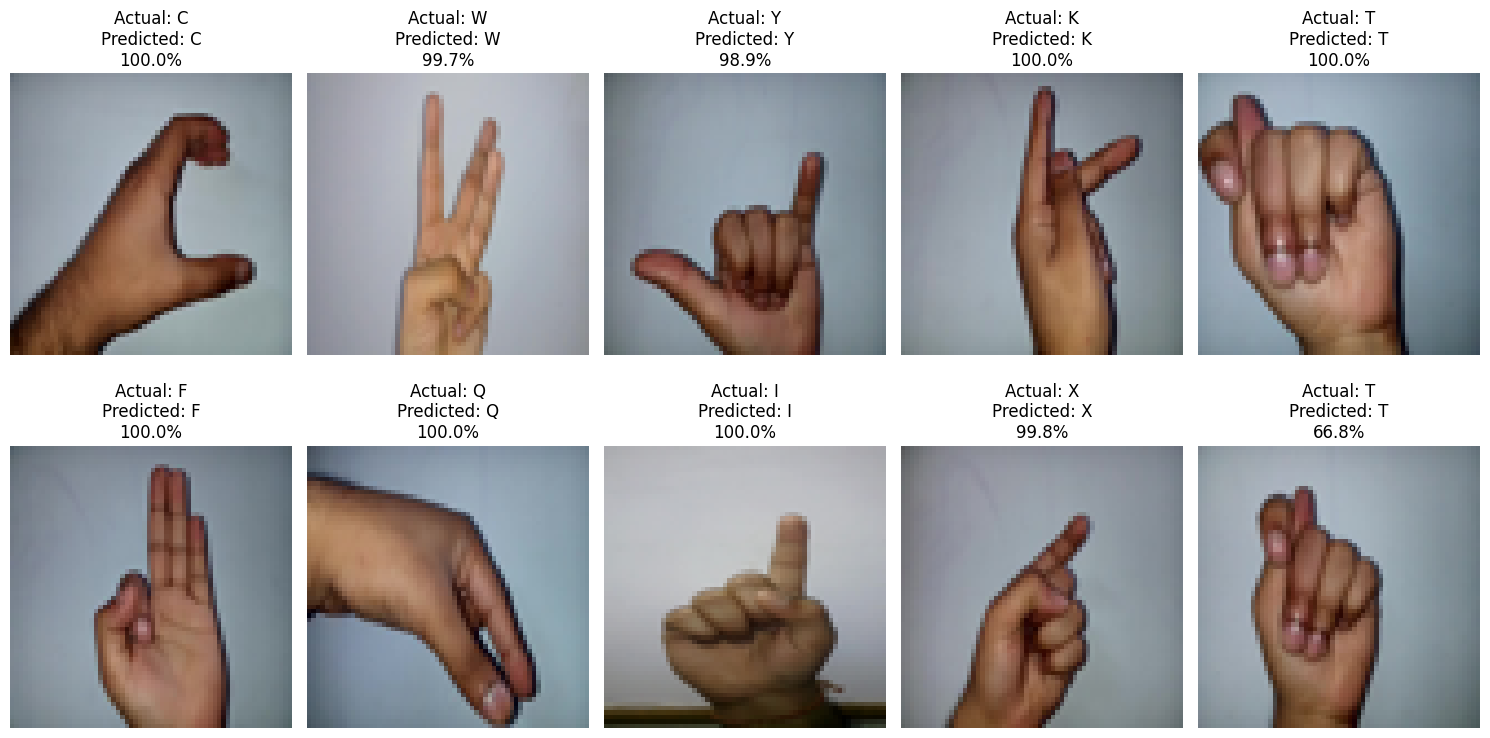

Correct Predictions: 10 / 10
Prediction Accuracy: 100 %


In [61]:
plt.figure(figsize=(15, 8))

correct_predictions = 0

for i in range(10):

    sample_image = X_test[i]
    actual_class = y_test[i]

    prediction = loaded_model.predict(
        np.expand_dims(sample_image, axis=0),
        verbose=0
    )

    predicted_class = np.argmax(prediction, axis=1)[0]

    actual_label = label_encoder.inverse_transform(
        [actual_class]
    )[0]

    predicted_label = label_encoder.inverse_transform(
        [predicted_class]
    )[0]

    confidence = np.max(prediction) * 100

    if actual_class == predicted_class:
        correct_predictions += 1

    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_image)
    plt.axis("off")
    plt.title(
        f"Actual: {actual_label}\n"
        f"Predicted: {predicted_label}\n"
        f"{confidence:.1f}%"
    )

plt.tight_layout()
plt.show()

print("Correct Predictions:", correct_predictions, "/ 10")
print("Prediction Accuracy:", correct_predictions * 10, "%")

### Create a Prediction Results Table

In [62]:
import pandas as pd
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

results = []

for i in range(10):

    sample_image = X_test[i]

    prediction = loaded_model.predict(
        np.expand_dims(sample_image, axis=0),
        verbose=0
    )

    predicted_class = np.argmax(prediction, axis=1)[0]

    actual_label = label_encoder.inverse_transform(
        [y_test[i]]
    )[0]

    predicted_label = label_encoder.inverse_transform(
        [predicted_class]
    )[0]

    confidence = np.max(prediction) * 100

    results.append({
        "Image": f"Test Image {i+1}",
        "Actual Sign": actual_label,
        "Predicted Sign": predicted_label,
        "Confidence (%)": round(confidence, 2),
        "Status": "Correct" if actual_label == predicted_label else "Incorrect"
    })

prediction_results = pd.DataFrame(results)
from IPython.display import display as show_table

show_table(prediction_results)

,Image,Actual Sign,Predicted Sign,Confidence (%),Status
0,Test Image 1,C,C,100.000000,Correct
1,Test Image 2,W,W,99.660004,Correct
2,Test Image 3,Y,Y,98.940002,Correct
3,Test Image 4,K,K,100.000000,Correct
4,Test Image 5,T,T,100.000000,Correct
5,Test Image 6,F,F,99.959999,Correct
6,Test Image 7,Q,Q,100.000000,Correct
7,Test Image 8,I,I,100.000000,Correct
8,Test Image 9,X,X,99.839996,Correct
9,Test Image 10,T,T,66.839996,Correct


### Calculate Prediction Accuracy

In [63]:
total_predictions = len(prediction_results)

correct = (prediction_results["Status"] == "Correct").sum()

incorrect = total_predictions - correct

accuracy = (correct / total_predictions) * 100

print("Total Predictions:", total_predictions)
print("Correct Predictions:", correct)
print("Incorrect Predictions:", incorrect)
print("Prediction Accuracy:", round(accuracy, 2), "%")

Total Predictions: 10
Correct Predictions: 10
Incorrect Predictions: 0
Prediction Accuracy: 100.0 %


### Predict a New External Image

In [67]:
from IPython.display import display
import ipywidgets as widgets

upload = widgets.FileUpload(
    accept='.jpg,.jpeg,.png',
    multiple=False
)

display(upload)

FileUpload(value=(), accept='.jpg,.jpeg,.png', description='Upload')

### Preprocess the uploaded image and predict

In [69]:
import numpy as np
from PIL import Image
import io

uploaded_file = upload.value

if isinstance(uploaded_file, dict):
    image_bytes = uploaded_file[list(uploaded_file.keys())[0]]['content']
else:
    image_bytes = uploaded_file[0]['content']

img = Image.open(io.BytesIO(image_bytes)).convert("RGB")

# Resize image to 64x64
img_resized = img.resize((64, 64))

# Normalize pixel values
img_array = np.array(img_resized).astype("float32") / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Predict the sign
prediction = loaded_model.predict(img_array, verbose=0)

predicted_class = np.argmax(prediction, axis=1)[0]

predicted_label = label_encoder.inverse_transform(
    [predicted_class]
)[0]

confidence = np.max(prediction) * 100

print("Predicted Alphabet:", predicted_label)
print("Confidence Score:", round(confidence, 2), "%")

Predicted Alphabet: E
Confidence Score: 99.9 %


### Visualize External Image Prediction

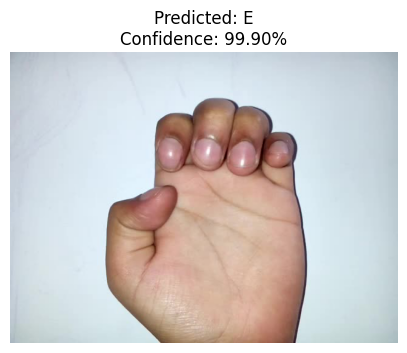

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")

plt.title(
    f"Predicted: {predicted_label}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()

### Create a Final Prediction Function with Confidence Status

In [71]:
external_prediction = pd.DataFrame([{
    "Image": "External Image",
    "Predicted Alphabet": predicted_label,
    "Confidence (%)": round(confidence, 2),
    "Confidence Status": (
        "High Confidence" if confidence >= 90
        else "Moderate Confidence" if confidence >= 70
        else "Low Confidence"
    )
}])

display(external_prediction)

,Image,Predicted Alphabet,Confidence (%),Confidence Status
0,External Image,E,99.900002,High Confidence


# 8. Initial Deployment

In [72]:
!pip install streamlit

   ---------------------------------------- 0.0/26.1 MB ? eta -:--:--
   ------ --------------------------------- 3.9/26.1 MB 20.0 MB/s eta 0:00:02
   ----------- ---------------------------- 7.6/26.1 MB 19.1 MB/s eta 0:00:01
   ----------------- ---------------------- 11.5/26.1 MB 18.9 MB/s eta 0:00:01
   ----------------------- ---------------- 15.2/26.1 MB 18.7 MB/s eta 0:00:01
   ----------------------------- ---------- 19.1/26.1 MB 18.7 MB/s eta 0:00:01
   ----------------------------------- ---- 23.1/26.1 MB 18.6 MB/s eta 0:00:01
   ---------------------------------------  26.0/26.1 MB 18.6 MB/s eta 0:00:01
   ---------------------------------------- 26.1/26.1 MB 17.0 MB/s  0:00:01
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 26.0.0
    Uninstalling pyarrow-26.0.0:
      Successfully uninstalled pyarrow-26.0.0


  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.1.0 requires pyarrow>=24.0.0, but you have pyarrow 21.0.0 which is incompatible.


In [73]:
import os

print("Model exists:",
      os.path.exists("saved_model/indisign_improved_cnn_model.keras"))

print("Classes file exists:",
      os.path.exists("prepared_data/classes.npy"))

Model exists: True
Classes file exists: True


### Create the Streamlit application file

In [74]:
%%writefile app.py

import streamlit as st
import numpy as np
import tensorflow as tf
from PIL import Image

# Load trained model
model = tf.keras.models.load_model(
    "saved_model/indisign_improved_cnn_model.keras"
)

# Load class labels
classes = np.load("prepared_data/classes.npy", allow_pickle=True)

st.title("IndiSign Language Recognition")
st.write("Upload a hand-sign image to predict its alphabet.")

uploaded_file = st.file_uploader(
    "Choose a hand-sign image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    img = Image.open(uploaded_file).convert("RGB")

    st.image(img, caption="Uploaded Hand Sign")

    # Preprocess image
    img_resized = img.resize((64, 64))
    img_array = np.array(img_resized).astype("float32") / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    prediction = model.predict(img_array, verbose=0)

    predicted_class = np.argmax(prediction, axis=1)[0]
    predicted_label = classes[predicted_class]
    confidence = np.max(prediction) * 100

    st.success(f"Predicted Alphabet: {predicted_label}")
    st.write(f"Confidence Score: {confidence:.2f}%")

Writing app.py


In [ ]:
!streamlit run app.py
# **http://localhost:8502/** this will show the output of my code

### Add project documentation

### Streamlit Web Application Deployment

The trained CNN model was successfully deployed using Streamlit.

The web application allows users to:
1. Upload a hand-sign image in JPG, JPEG, or PNG format.
2. View the uploaded image.
3. Predict the corresponding Indian Sign Language alphabet.
4. View the prediction confidence score.

The application runs locally using Streamlit at http://localhost:8502/.

The deployment demonstrates how a trained deep learning model can be integrated into an interactive web application.

# 9. Project Documentation and Conclusion

## Project Limitations

1. The model is trained on a limited dataset of 24 alphabet classes.
2. The dataset does not include the letters J and Z.
3. Prediction accuracy may decrease when images have different lighting, backgrounds, hand positions, or orientations.
4. The model currently recognizes static hand gestures only.
5. The application requires further testing with real-world images and different users.
6. The model's confidence score does not guarantee that a prediction is correct.

## Future Enhancements

1. Expand the dataset to include more hand-sign classes.
2. Add support for dynamic sign language recognition using video and sequence models such as LSTM.
3. Improve model generalization using more diverse images.
4. Develop a real-time recognition system using a webcam.
5. Deploy the application on a cloud platform.
6. Add text-to-speech functionality to improve accessibility.

## Conclusion

The IndiSign Language Recognition project successfully demonstrates the use of Deep Learning and Convolutional Neural Networks (CNNs) for recognizing static hand-sign alphabets.

The dataset was explored, preprocessed, and divided into training, validation, and testing sets. A baseline CNN model and an improved CNN model were developed and evaluated.

The improved model achieved approximately 99.50% test accuracy on the prepared test dataset. The trained model was then integrated into a Streamlit web application that allows users to upload hand-sign images and receive alphabet predictions with confidence scores.

This project demonstrates the practical application of computer vision and deep learning in developing an accessible sign language recognition system.